# Chapter 01 - Signals and Systems

## Example 1.1 Classifying Energy and Power Signals

Determine the appropriate measure for each signal in Fig. 1.2: energy or average power.

Source: *Linear Systems and Signals*, B. P. Lathi and Roger Green, printed page 67 (PDF page 87).

**(a)** A constant pulse followed by exponential decay:

$$x_a(t)=\begin{cases}
0, & t < -1,\\
2, & -1 \leq t < 0,\\
2e^{-t/2}, & t \geq 0.
\end{cases}$$

**(b)** A periodic ramp with period $T_0=2$:

$$x_b(t)=t,\quad -1\leq t<1,\qquad x_b(t+2)=x_b(t).$$

The half-open interval defines the values at jumps. Changing values at isolated points does not affect energy or power.

### Solution formulas 1.1

For continuous-time signals, the definitions are:

$$E_x=\int_{-\infty}^{\infty}|x(t)|^2\,dt,\qquad
P_x=\lim_{T\to\infty}\frac{1}{T}\int_{-T/2}^{T/2}|x(t)|^2\,dt.$$

An energy signal satisfies $0<E_x<\infty$ and has $P_x=0$.
A power signal satisfies $0<P_x<\infty$ and has infinite energy.
For a periodic signal, calculate power over a single period:

$$P_x=\frac{1}{T_0}\int_{t_0}^{t_0+T_0}|x(t)|^2\,dt,
\qquad x_{\mathrm{rms}}=\sqrt{P_x}.$$

In part (a), split the integral over the nonzero segments. In part (b), use the period $[-1,1)$.

In [1]:
import sympy as sym
from IPython.display import Math, display

t = sym.symbols("t", real=True)

# (a) Exact integrals: constant segment and exponential tail.
constant_energy = sym.integrate(sym.Integer(2) ** 2, (t, -1, 0))
tail_energy = sym.integrate((2 * sym.exp(-t / 2)) ** 2, (t, 0, sym.oo))
energy_a = constant_energy + tail_energy
power_a = sym.Integer(0)  # Finite energy implies zero average power.

# (b) The ramp equals t over one period of length 2.
period_b = sym.Integer(2)
energy_per_period_b = sym.integrate(t ** 2, (t, -1, 1))
power_b = energy_per_period_b / period_b
rms_b = sym.sqrt(power_b)
energy_b = sym.oo  # Each period contributes the same positive energy.

for expression, result in [
    (r"E_a", energy_a),
    (r"P_a", power_a),
    (r"E_b", energy_b),
    (r"P_b", power_b),
    (r"x_{b,\mathrm{rms}}", rms_b),
]:
    display(Math(rf"{expression} = {sym.latex(result)}"))

print(f"(a) Energy signal: E = {energy_a}; P = {power_a}.")
print(f"(b) Power signal: P = {float(power_b):.4f}; rms = {float(rms_b):.4f}.")

(a) Energy signal: E = 8; P = 0.
(b) Power signal: P = 0.3333; rms = 0.5774.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Graphical solution 1.1

Use NumPy to represent the signals and Matplotlib to plot them.
The magnitude operation maps time to the interval $[-1,1)$ for the periodic signal:

$$x_b(t)=\big((t+1)\bmod 2\big)-1.$$

The right panels show $|x(t)|^2$. The total area in part (a) is the energy;
in part (b), divide the area of one period by $T_0$ to obtain the power.
The plot in (a) shows only part of the tail; the symbolic integral extends to infinity.

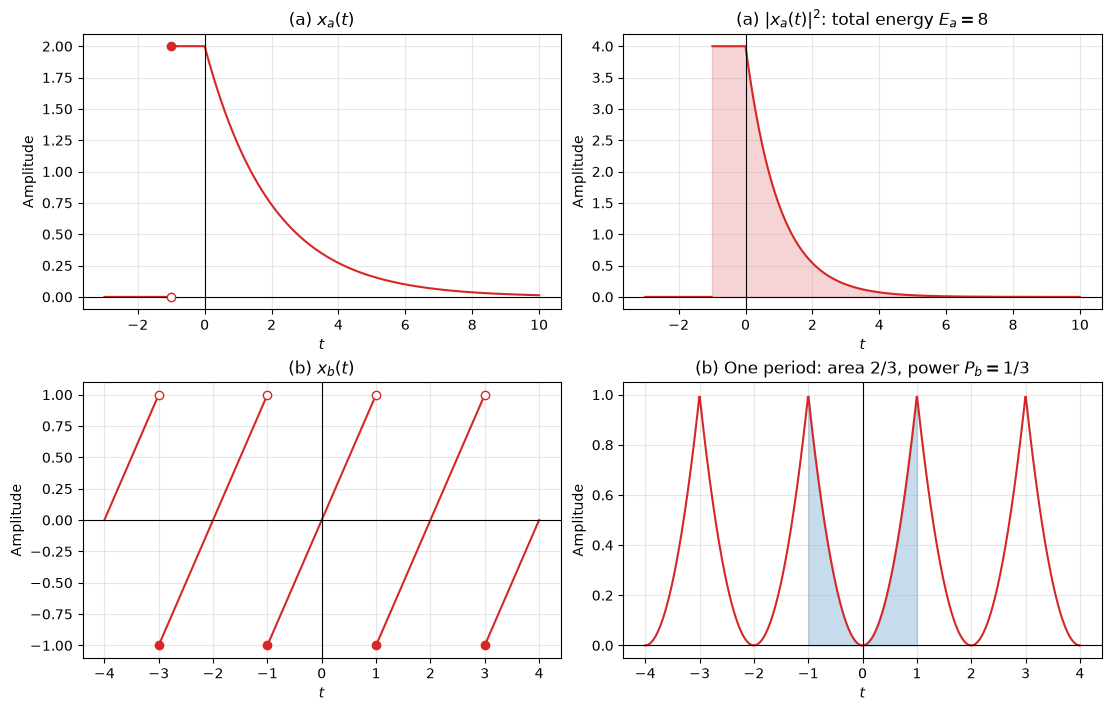

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# (a) Evaluate the exponential only on the segment where it applies.
t_a = np.linspace(-3, 10, 1301)
x_a = np.zeros_like(t_a)
x_a[(t_a >= -1) & (t_a < 0)] = 2
tail = t_a >= 0
x_a[tail] = 2 * np.exp(-t_a[tail] / 2)

# (b) Periodic extension of the ramp defined on [-1, 1).
t_b = np.linspace(-4, 4, 1601)
x_b = (t_b + 1) % 2 - 1

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")

for row, time, signal, item in zip(axes, [t_a, t_b], [x_a, x_b], "ab"):
    for ax, amplitude, title in zip(
        row, [signal, np.abs(signal) ** 2],
        [rf"({item}) $x_{item}(t)$", rf"({item}) $|x_{item}(t)|^2$"],
    ):
        # Break the line at jumps to avoid drawing artificial segments.
        curve = amplitude.copy()
        jumps = np.diff(signal) < -1 if item == "b" else np.diff(signal) > 1
        curve[np.flatnonzero(jumps) + 1] = np.nan
        ax.plot(time, curve, color="tab:red")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set(title=title, xlabel="$t$", ylabel="Amplitude")
        ax.grid(alpha=0.3)

# Markers distinguish excluded endpoints from values at jumps.
axes[0, 0].plot(-1, 0, "o", mfc="white", mec="tab:red")
axes[0, 0].plot(-1, 2, "o", color="tab:red")
for jump in (-3, -1, 1, 3):
    axes[1, 0].plot(jump, 1, "o", mfc="white", mec="tab:red")
    axes[1, 0].plot(jump, -1, "o", color="tab:red")

axes[0, 1].fill_between(t_a, x_a ** 2, where=t_a >= -1,
                        color="tab:red", alpha=0.2)
axes[0, 1].set_title(r"(a) $|x_a(t)|^2$: total energy $E_a=8$")

# Include both endpoints to shade exactly one period.
t_period = np.linspace(-1, 1, 401)
axes[1, 1].fill_between(t_period, t_period ** 2, color="tab:blue", alpha=0.25)
axes[1, 1].set_title(r"(b) One period: area $2/3$, power $P_b=1/3$")

plt.show()

### Results 1.1

**(a)** The energy is finite:

$$E_a=\int_{-1}^{0}4\,dt+\int_0^\infty4e^{-t}\,dt=4+4=8.$$

Therefore, $x_a(t)$ is an **energy signal**, with average power $P_a=0$.
The classification follows from convergence of the integral; amplitude decay alone does not guarantee finite energy.

**(b)** The energy per period is $2/3$. Since the signal repeats indefinitely, $E_b=\infty$.
Its average power is finite:

$$P_b=\frac{1}{2}\int_{-1}^{1}t^2\,dt=\frac{1}{3},
\qquad x_{b,\mathrm{rms}}=\frac{1}{\sqrt{3}}\approx0.5774.$$

Therefore, $x_b(t)$ is a **power signal**.

These are signal energy and power measures, without assuming a specific physical unit or electrical load.